# Assignment 6 – IMDB Movie Review Sentiment Classification
**Task:** Binary classification (positive / negative) of movie reviews.
**Dataset:** [IMDB Dataset – Sentiment Analysis in CSV format (Kaggle)](https://www.kaggle.com/datasets/columbine/imdb-dataset-sentiment-analysis-in-csv-format) – `Train.csv` (40k), `Valid.csv` (5k), `Test.csv` (5k), columns `text`, `label` (1 = positive, 0 = negative). Ground truth labels are provided, so every model can be validated.

**Models compared**
1. **Model 1 – Neural network (MLP)** on TF-IDF uni+bi-gram features
2. **Model 2 – Deep learning (Bidirectional LSTM)** on learned word embeddings

**Metrics:** Precision, Recall, F1, AUC-ROC (plus accuracy and confusion matrix).

> Run on Google Colab with GPU (Runtime → Change runtime type → T4 GPU).

In [1]:
!pip -q install kagglehub
import os, re, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

SEED = 42
tf.keras.utils.set_random_seed(SEED)
os.makedirs("results", exist_ok=True)
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: []


## 1. Load dataset

In [2]:
import kagglehub
path = kagglehub.dataset_download("columbine/imdb-dataset-sentiment-analysis-in-csv-format")
print("Downloaded to:", path)
# If kagglehub fails: download the zip from Kaggle, upload Train/Valid/Test.csv to Colab, and set path = "."

train = pd.read_csv(os.path.join(path, "Train.csv"))
valid = pd.read_csv(os.path.join(path, "Valid.csv"))
test  = pd.read_csv(os.path.join(path, "Test.csv"))
print(train.shape, valid.shape, test.shape)
train.head()

c:\Users\ybaav\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloaded to: C:\Users\ybaav\.cache\kagglehub\datasets\columbine\imdb-dataset-sentiment-analysis-in-csv-format\versions\1
(40000, 2) (5000, 2) (5000, 2)


,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


## 2. Quick look + preprocessing
Reviews contain HTML tags such as `<br />`; we strip them, lowercase and normalise whitespace.

Class balance (train):
 label
0    0.5
1    0.5
Name: proportion, dtype: float64
Avg words per review: 229.1


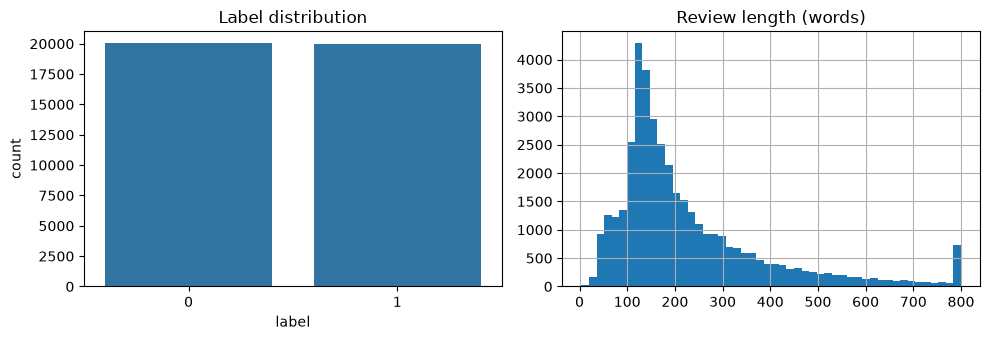

In [3]:
def clean(t):
    t = re.sub(r"<[^>]+>", " ", str(t))
    t = re.sub(r"\s+", " ", t).strip().lower()
    return t

for df in (train, valid, test):
    df["text"] = df["text"].map(clean)

print("Class balance (train):\n", train["label"].value_counts(normalize=True).round(3))
print("Avg words per review:", train["text"].str.split().str.len().mean().round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="label", data=train, ax=ax[0]); ax[0].set_title("Label distribution")
train["text"].str.split().str.len().clip(upper=800).hist(bins=50, ax=ax[1]); ax[1].set_title("Review length (words)")
plt.tight_layout(); plt.savefig("results/eda.png", dpi=150); plt.show()

In [4]:
X_train, y_train = train["text"].values, train["label"].values.astype("float32")
X_valid, y_valid = valid["text"].values, valid["label"].values.astype("float32")
X_test,  y_test  = test["text"].values,  test["label"].values.astype("float32")
BATCH = 128
AUTO = tf.data.AUTOTUNE

def make_ds(X, y, vec, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(10_000, seed=SEED)
    return ds.batch(BATCH).map(lambda a, b: (vec(a), b), num_parallel_calls=AUTO).prefetch(AUTO)

## 3. Model 1 – Neural network (MLP) on TF-IDF features
Each review becomes a 20,000-dimensional TF-IDF vector (unigrams + bigrams). A feed-forward network with dropout learns a non-linear decision boundary over word-presence evidence. It ignores word order but is fast and a strong baseline for sentiment.

In [5]:
tfidf = layers.TextVectorization(max_tokens=20_000, ngrams=2, output_mode="tf_idf")
tfidf.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(512))

tr1 = make_ds(X_train, y_train, tfidf, shuffle=True)
va1 = make_ds(X_valid, y_valid, tfidf)
te1 = make_ds(X_test,  y_test,  tfidf)

mlp = models.Sequential([
    layers.Input(shape=(20_000,)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
], name="tfidf_mlp")
mlp.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
            metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
mlp.summary()

hist1 = mlp.fit(tr1, validation_data=va1, epochs=10,
                callbacks=[callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_loss")])

Model: "tfidf_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     5,120,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,136,769 (19.60 MB)

 Trainable params: 5,136,769 (19.60 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


c:\Users\ybaav\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - accuracy: 0.8309 - auc: 0.8976 - loss: 0.4584 - val_accuracy: 0.9036 - val_auc: 0.9638 - val_loss: 0.2498
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 111ms/step - accuracy: 0.9209 - auc: 0.9724 - loss: 0.2131 - val_accuracy: 0.8996 - val_auc: 0.9660 - val_loss: 0.2418
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 146ms/step - accuracy: 0.9455 - auc: 0.9860 - loss: 0.1486 - val_accuracy: 0.9040 - val_auc: 0.9624 - val_loss: 0.2825
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 127ms/step - accuracy: 0.9603 - auc: 0.9920 - loss: 0.1097 - val_accuracy: 0.9036 - val_auc: 0.9631 - val_loss: 0.2824


## 4. Model 2 – Deep learning: Bidirectional LSTM
Reviews are converted to integer sequences (max 256 tokens), embedded into 128-d learned vectors, and read in both directions by an LSTM. Unlike the MLP it models **word order and context** (e.g. "not good", "good, but boring").

In [6]:
MAX_TOKENS, SEQ_LEN = 20_000, 256
int_vec = layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode="int", output_sequence_length=SEQ_LEN)
int_vec.adapt(tf.data.Dataset.from_tensor_slices(X_train).batch(512))

tr2 = make_ds(X_train, y_train, int_vec, shuffle=True)
va2 = make_ds(X_valid, y_valid, int_vec)
te2 = make_ds(X_test,  y_test,  int_vec)

bilstm = models.Sequential([
    layers.Input(shape=(SEQ_LEN,), dtype="int64"),
    layers.Embedding(MAX_TOKENS, 128, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
], name="bilstm")
bilstm.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
               metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
bilstm.summary()

hist2 = bilstm.fit(tr2, validation_data=va2, epochs=6,
                   callbacks=[callbacks.EarlyStopping(patience=2, restore_best_weights=True, monitor="val_loss")])

Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,137 (10.17 MB)

 Trainable params: 2,667,137 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 376s 1s/step - accuracy: 0.8123 - auc: 0.9034 - loss: 0.3920 - val_accuracy: 0.8826 - val_auc: 0.9524 - val_loss: 0.2816
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 310s 989ms/step - accuracy: 0.9193 - auc: 0.9720 - loss: 0.2118 - val_accuracy: 0.8806 - val_auc: 0.9501 - val_loss: 0.2972
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 307s 981ms/step - accuracy: 0.9529 - auc: 0.9886 - loss: 0.1309 - val_accuracy: 0.8748 - val_auc: 0.9467 - val_loss: 0.3618


## 5. Training curves

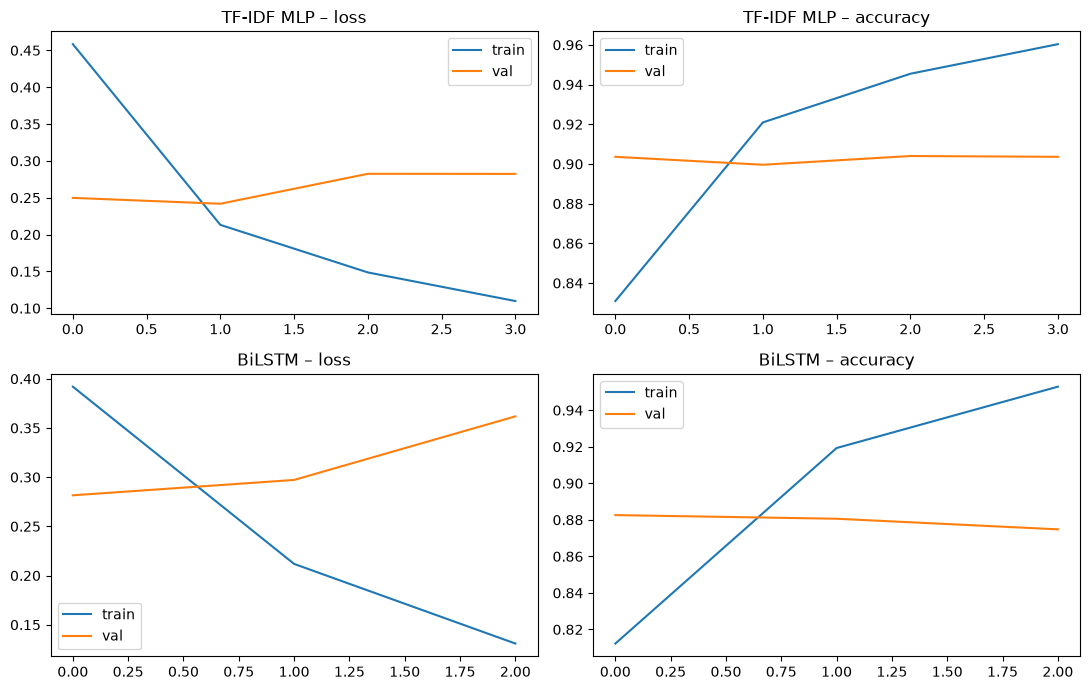

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for row, (name, h) in enumerate([("TF-IDF MLP", hist1), ("BiLSTM", hist2)]):
    ax[row,0].plot(h.history["loss"], label="train"); ax[row,0].plot(h.history["val_loss"], label="val")
    ax[row,0].set_title(f"{name} – loss"); ax[row,0].legend()
    ax[row,1].plot(h.history["accuracy"], label="train"); ax[row,1].plot(h.history["val_accuracy"], label="val")
    ax[row,1].set_title(f"{name} – accuracy"); ax[row,1].legend()
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=150); plt.show()

## 6. Evaluation on the held-out test set
Precision, Recall, F1 and AUC-ROC (threshold = 0.5).

In [8]:
def evaluate(name, y_true, y_prob, thr=0.5):
    y_pred = (y_prob >= thr).astype(int)
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=["negative", "positive"], digits=4))
    return {"Model": name,
            "Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall":    recall_score(y_true, y_pred),
            "F1":        f1_score(y_true, y_pred),
            "AUC-ROC":   roc_auc_score(y_true, y_prob)}

p1 = mlp.predict(te1, verbose=0).ravel()
p2 = bilstm.predict(te2, verbose=0).ravel()

results = pd.DataFrame([evaluate("TF-IDF MLP", y_test, p1),
                        evaluate("BiLSTM",     y_test, p2)]).round(4)
results.to_csv("results/metrics.csv", index=False)
results


===== TF-IDF MLP =====
              precision    recall  f1-score   support

    negative     0.9339    0.8657    0.8985      2495
    positive     0.8753    0.9389    0.9060      2505

    accuracy                         0.9024      5000
   macro avg     0.9046    0.9023    0.9023      5000
weighted avg     0.9045    0.9024    0.9023      5000


===== BiLSTM =====
              precision    recall  f1-score   support

    negative     0.8945    0.8770    0.8857      2495
    positive     0.8798    0.8970    0.8883      2505

    accuracy                         0.8870      5000
   macro avg     0.8872    0.8870    0.8870      5000
weighted avg     0.8871    0.8870    0.8870      5000



,Model,Accuracy,Precision,Recall,F1,AUC-ROC
0,TF-IDF MLP,0.9024,0.8753,0.9389,0.9060,0.9640
1,BiLSTM,0.8870,0.8798,0.8970,0.8883,0.9527


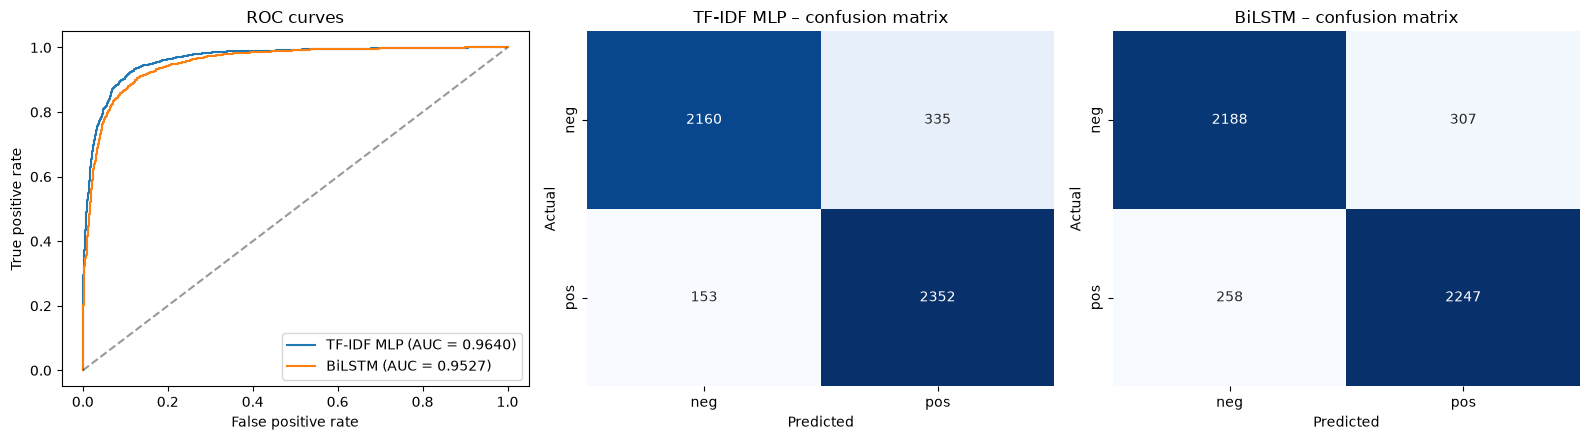

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# ROC curves
for name, p in [("TF-IDF MLP", p1), ("BiLSTM", p2)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.4f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves"); ax[0].legend(loc="lower right")

# Confusion matrices
for a, (name, p) in zip(ax[1:], [("TF-IDF MLP", p1), ("BiLSTM", p2)]):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
    a.set_title(f"{name} – confusion matrix"); a.set_xlabel("Predicted"); a.set_ylabel("Actual")

plt.tight_layout(); plt.savefig("results/roc_confusion.png", dpi=150); plt.show()

## 7. Discussion (fill in with your actual numbers after running)
- Compare the two rows of the metrics table: which model has the higher F1 and AUC-ROC?
- Check precision vs recall for each model – is either biased toward one class? (see confusion matrices)
- TF-IDF MLP: fast, strong on explicit sentiment words/bigrams, but blind to word order and long-range context.
- BiLSTM: captures order and negation, but truncates at 256 tokens and trains slower; may overfit (see training curves).
- The dataset is balanced, so accuracy, F1 and AUC-ROC should tell a consistent story.